# 📈 Relatório de Exportações de Vinhos Brasileiros

## 1. Introdução
O objetivo dessa análise é trazer informação consolidada sobre o cenário de exportação de vinhos brasileiros nos últimos 15 anos, habilitando a tomada de decisão para novos investimentos e apresentação da situação atual da companhia para os acionistas, baseando-se em data driven.

## 2. Base de Dados
Tema: **Exportações por países**  
Período analisado: **2009–2023**  
Métrica: **Valor exportado (US$)**  
Fonte: **Embrapa / VitiBrasil**  
(https://vitibrasil.cnpuv.embrapa.br/index.php?opcao=opt_01)

## 3. Contexto
Durante a extração dos dados, foram consideradas as bases de Produção, Comercialização e Exportação; no entanto, essas tinham pouca sinergia entre elas, pois os dados de Produção e Comercialização trazem apenas o tipo dos vinhos e a quantidade produzida/comercializada no Rio Grande do Sul, que na prática, faz pouco sentido comparar a quantidade distribuída no RS contra a exportação em outros países; temos diferenças de gostos, culturais, etc.

Também foi considerada a utilização da produção para avaliar a correlação entre produção e exportação, embora exista um forte indício, não há clareza nos dados para realizar essa análise, pois a base de produção traz os tipos **VINHO DE MESA** e **VINHO FINO DE MESA**, enquanto que a base de exportação traz todos os tipos consolidados em **VINHO DE MESA**, tornando difícil a interpretação com risco de falso-positivo; portanto, a análise foi desconsiderada.

Por fim, foi utilizada apenas a base de exportação dos últimos 15 anos, que traz informação de ano, país de destino, valor (US$), quantidade (kg).

In [1]:
#Imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
# O Jupyter pode iniciar o kernel em notebooks/ ou na raiz do projeto.
data_dir = Path("data")
if not data_dir.is_dir():
    data_dir = Path("../data")

dataframes = {
    name: pd.read_csv(data_dir / f"{name}.csv", sep=";")
    for name in ("Comercio", "Producao", "ExpVinho")
}

In [3]:
#Tabela de comercio FMT----------------------------------------
df_comercio = dataframes["Comercio"]
df_comercio = df_comercio[df_comercio["id"] < 9]
df_comercio = df_comercio.melt(
    id_vars=["id", "control", "Produto"],  
    var_name="ano",                       
    value_name="valor"                   
)
df_comercio = df_comercio.rename(columns={"Produto": "produto", "Id": "id"})
df_comercio = df_comercio[df_comercio["ano"].astype(int) > 2008]

In [4]:
#Tabela de producao FMT----------------------------------------
df_producao = dataframes["Producao"].copy()

# Corrigir nomes de colunas (antes do melt)
df_producao.columns = (
    df_producao.columns
    .astype(str)              # garante que tudo é string
    .str.strip()              # remove espaços
    .str.replace(".0", "", regex=False)  # remove sufixo .0
    .str.replace(".1", "", regex=False)  # remove sufixo .1
)

df_producao = df_producao.melt(
    id_vars=["id", "tipo", "produto"],  
    var_name="ano",                       
    value_name="valor"                   
)
df_producao = df_producao[df_producao["ano"].astype(int) > 2008]

In [5]:
#Tabela de exportacao FMT----------------------------------------
df_exportacao = dataframes["ExpVinho"].copy()

# Corrigir nomes de colunas (antes do melt)
df_exportacao.columns = (
    df_exportacao.columns
    .astype(str)              # garante que tudo é string
    .str.strip()              # remove espaços
    .str.replace(".0", ".qtd", regex=False)  # remove sufixo .0
    .str.replace(".1", ".vlr", regex=False)  # remove sufixo .1
)

# Identificar colunas de quantidade (.qtd) e valor (.vlr)
cols_vlr = [c for c in df_exportacao.columns if c.endswith(".vlr")]
cols_qtd = [c.replace(".vlr", "") for c in cols_vlr]

# --- Melt para transformar quantidade ---
df_qtd = df_exportacao.melt(
    id_vars=["Id", "País"],
    value_vars=cols_qtd,
    var_name="ano",
    value_name="quantidade"
)

# Remover o sufixo .qtd para deixar só o ano
df_qtd["ano"] = df_qtd["ano"].str.replace(".qtd", "", regex=False)

# --- Melt para transformar valor ---
df_vlr = df_exportacao.melt(
    id_vars=["Id", "País"],
    value_vars=cols_vlr,
    var_name="ano",
    value_name="valor"
)

# Remover o sufixo .vlr
df_vlr["ano"] = df_vlr["ano"].str.replace(".vlr", "", regex=False)

# --- Combinar quantidade e valor (merge) ---
df_exportacao = pd.merge(
    df_qtd,
    df_vlr,
    on=["Id", "País", "ano"],
    how="outer"
)

# Ajustes finais
df_exportacao["ano"] = pd.to_numeric(df_exportacao["ano"], errors="coerce").astype("Int64")
df_exportacao = df_exportacao.dropna(subset=["ano"])
df_exportacao["ano"] = df_exportacao["ano"].astype(int)

# Renomear colunas para padrão uniforme e filtros
df_exportacao = df_exportacao.rename(columns={"País": "pais_destino", "Id": "id"})
df_exportacao = df_exportacao[df_exportacao["ano"].astype(int) > 2008]
df_exportacao["pais_origem"] = "Brasil"
df_exportacao = df_exportacao[["id", "ano", "pais_origem", "pais_destino", "quantidade", "valor"]]

In [6]:
# Total por país (acumulado nos últimos 15 anos)
agg_country = df_exportacao.groupby('pais_destino').agg(
    quantidade_kg=('quantidade', 'sum'),
    valor_usd=('valor', 'sum')
).reset_index().sort_values('valor_usd', ascending=False)

agg_country_year = df_exportacao.groupby(['pais_destino', 'ano']).agg(
    kg=('quantidade', 'sum'),
    valor_usd=('valor', 'sum')
).reset_index()

pivot_valor = agg_country_year.pivot(index='ano', columns='pais_destino', values='valor_usd').fillna(0)
pivot_kg = agg_country_year.pivot(index='ano', columns='pais_destino', values='kg').fillna(0)

top_n = 20
table_top_countries = agg_country.head(top_n)
# display(table_top_countries)

## 4. Analises  
#### 4.1 - Montante de vendas (US$) nos ultimos 15 anos  

Na primeira análise temos o montante de exportações em valores (US$) nos últimos 15 anos, de imediato, são mais evidentes os 3 primeiros: Paraguai, Rússia e EUA, que destoam muito dos demais.

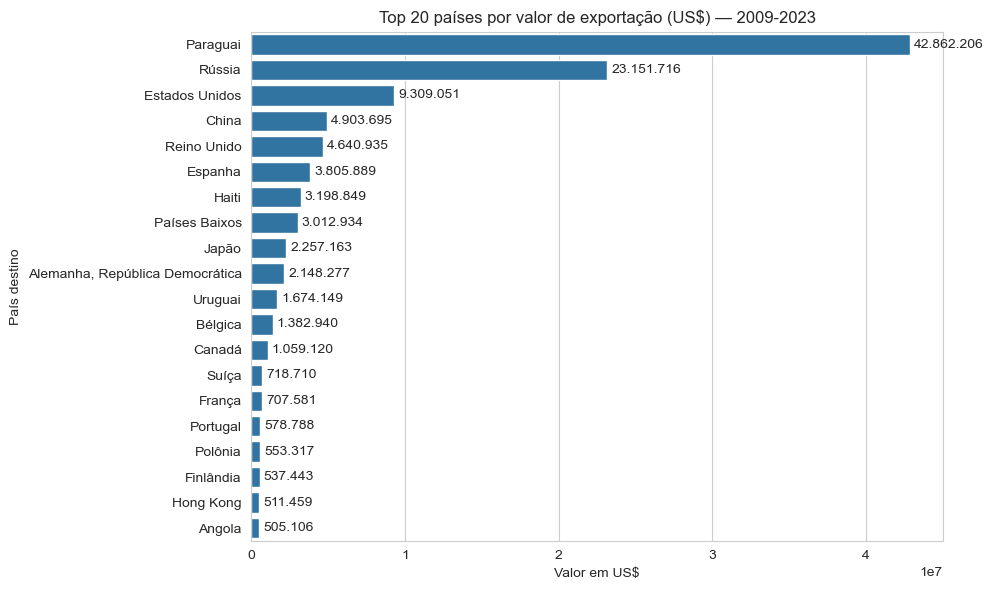

In [7]:
#Valor (US$) de exportacoes por barras
sns.set_style('whitegrid')

max_year = df_exportacao["ano"].max()
min_year = df_exportacao["ano"].min()
top_n = len(table_top_countries)  # opcional, se quiser usar na legenda

# Top países por valor
plt.figure(figsize=(10,6))
ax = sns.barplot(data=table_top_countries, x='valor_usd', y='pais_destino')

plt.title(f"Top {top_n} países por valor de exportação (US$) — {min_year}-{max_year}")
plt.xlabel("Valor em US$")
plt.ylabel("País destino")

# Adicionar rótulos formatados com ponto como separador
for container in ax.containers:
    labels = [f"{int(v):,}".replace(",", ".") for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

plt.tight_layout()
plt.show()

#### 4.2 - TOP 6 Evolucao da exportacao por paises destino

Após evidenciar os 3 maiores países de exportação (Paraguai, Rússia e EUA), foi prudente entender como se deu essa evolução ao longo dos anos e para surpresa, a Rússia se tornou um outlier nessa análise, pois houve um grande volume de exportação entre 2012 e 2014 e não se manteve para os anos seguintes.  

Também podemos notar como as exportações do Paraguai cresceram e se distanciaram muito dos outros países, achatando todas as outras análises.

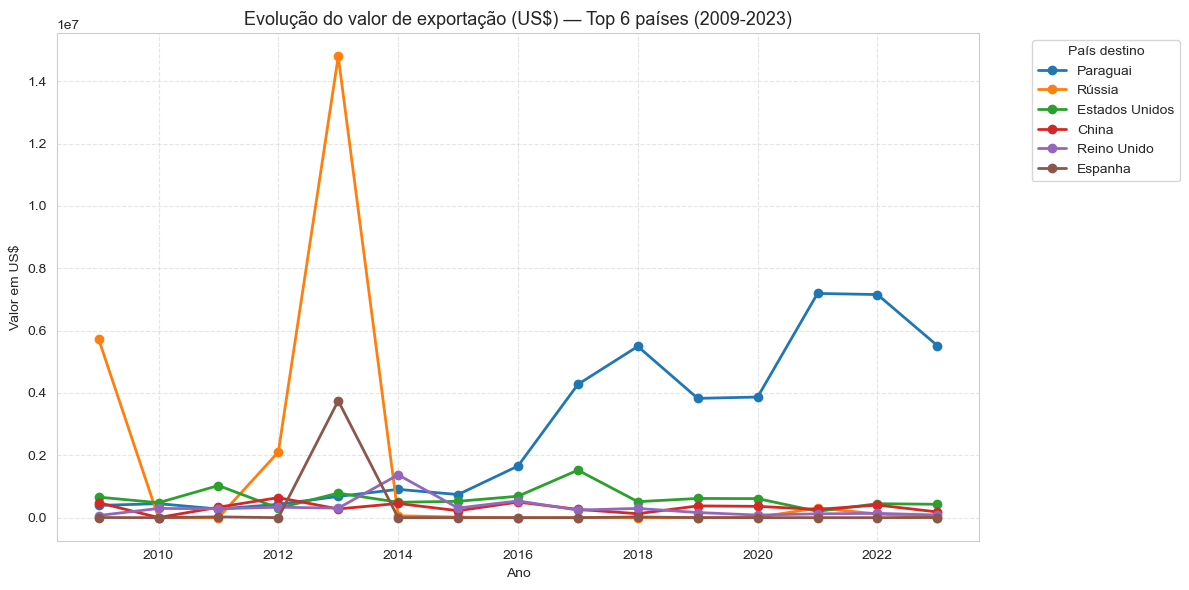

In [8]:
#Valor (US$) de exportacoes por paises
top6 = table_top_countries['pais_destino'].head(6).tolist()

plt.figure(figsize=(12,6))
for pais in top6:
    if pais in pivot_valor.columns:
        plt.plot(pivot_valor.index, pivot_valor[pais], marker='o', linewidth=2, label=pais)

plt.title(f"Evolução do valor de exportação (US$) — Top 6 países ({min_year}-{max_year})", fontsize=13)
plt.xlabel("Ano")
plt.ylabel("Valor em US$")
plt.legend(title="País destino", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### 4.3 - TOP 6 Evolucao da exportacao por paises destino (Logaritimica) e previsao futura

Transformei a visualização anterior (4.2) em escala logarítmica, a fim de equalizar as evoluções e habilitar a análise para todos paises. Tambem foi incluido uma previsão de exportações (tracejado) até 2028 utilizando o modelo de regressão linear.  

Aqui confirmamos que as exportações para o Paraguai apresentam forte tendencia de crescimento, mas exportações para a Rússia de fato não se mantêm fortes para os anos seguintes e também as exportações para os países EUA, China e Reino Unido seguem com tendência de queda, conforme previsão apresentada na tabela abaixo:

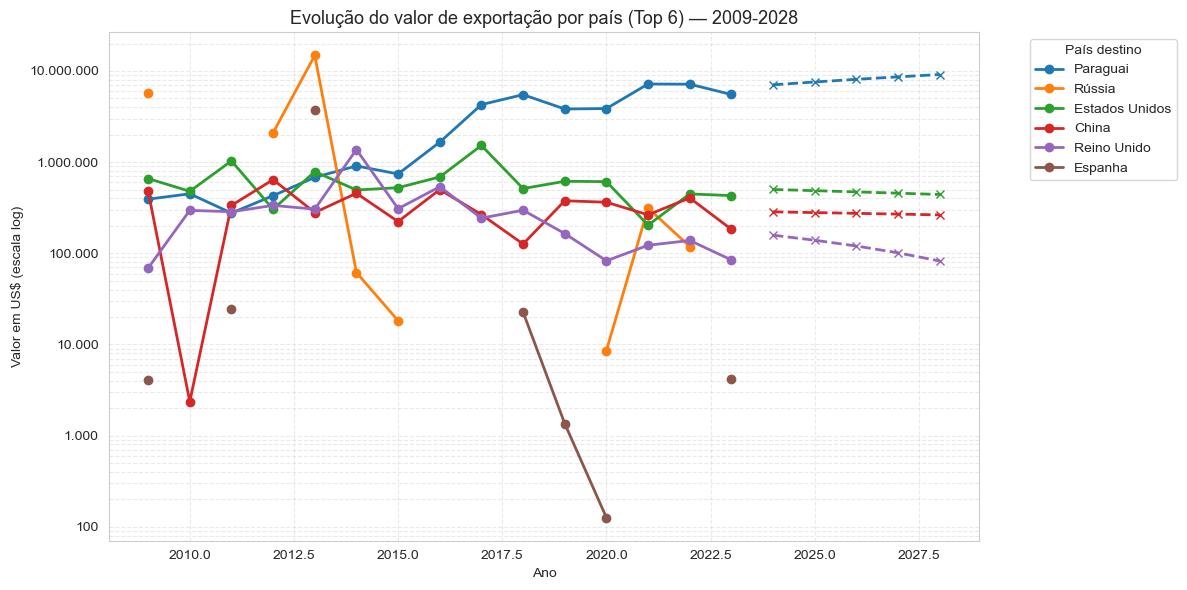

In [9]:
sns.set_style("whitegrid")

# Top 6
top6 = table_top_countries['pais_destino'].head(6).tolist()

# Paleta / mapeamento de cores (garante cor fixa por país)
palette = sns.color_palette(n_colors=len(top6))
color_map = {pais: palette[i] for i, pais in enumerate(top6)}

plt.figure(figsize=(12,6))
ax = plt.gca()

forecast_results = []

# Para cada país: fit linear e prever 5 anos
n_periods = 5
# define last_year antes do loop (usado para criar future_years consistente)
last_year = int(pivot_valor.index.max())

for pais in top6:
    if pais not in pivot_valor.columns:
        continue

    # série anual (pode conter NaN)
    s = pivot_valor[pais].replace(0, np.nan)

    # selecionar anos com dado (X) e valores (y) para treinar
    mask = s.notna()
    if mask.sum() < 3:
        # pula se poucos pontos
        continue

    X_years = pivot_valor.index.values[mask].reshape(-1, 1)   # ex: array([2008,2009,...]) -> shape (n,1)
    y_vals = s[mask].values

    # Treinar Regressão Linear
    model = LinearRegression()
    model.fit(X_years, y_vals)

    # Previsão para próximos n_periods anos
    future_years = np.arange(last_year + 1, last_year + n_periods + 1).reshape(-1, 1)
    forecast = model.predict(future_years)

    # Corrigir previsões negativas (clamp em 0)
    forecast_clipped = np.clip(forecast, a_min=0, a_max=None)

    # Para plotagem em escala log, evitar zeros (não plota zeros) -> usar NaN para não desenhar pontos negativos/zero
    forecast_plot = np.where(forecast_clipped > 0, forecast_clipped, np.nan)

    # Guardar previsões (usar os valores originais clipados)
    df_temp = pd.DataFrame({
        "pais_destino": pais,
        "ano": future_years.flatten(),
        "valor_previsto": forecast_clipped
    })
    forecast_results.append(df_temp)

    # Plot histórico (série original, com NaNs mantendo gaps)
    ax.plot(pivot_valor.index, s, marker='o', linewidth=2, label=pais, color=color_map[pais])

    # Plot previsão com mesma cor (tracejada). usa forecast_plot para não tentar plotar zeros
    ax.plot(future_years.flatten(), forecast_plot, linestyle='--', marker='x', linewidth=2, color=color_map[pais])

# Título e labels
ax.set_title(f"Evolução do valor de exportação por país (Top 6) — {min_year}-{last_year + n_periods}", fontsize=13)
ax.set_xlabel("Ano")
ax.set_ylabel("Valor em US$ (escala log)")

# Escala logarítmica
ax.set_yscale('log')

# Formatação do eixo Y (separador de milhar com ponto)
def br_formatter(x, pos):
    try:
        return f"{int(x):,}".replace(",", ".")
    except Exception:
        return f"{x:.0f}"
ax.yaxis.set_major_formatter(mtick.FuncFormatter(br_formatter))

# Legenda à direita
ax.legend(title="País destino", bbox_to_anchor=(1.05, 1), loc='upper left')

# Grade e layout
ax.grid(True, which="both", linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Consolidar previsões em um único DataFrame
if forecast_results:
    df_forecast_linear = pd.concat(forecast_results, ignore_index=True)
else:
    df_forecast_linear = pd.DataFrame(columns=["pais_destino", "ano", "valor_previsto"])

# Remover notação científica e formatar para exibição (estilo BR)
df_forecast_linear['valor_previsto'] = df_forecast_linear['valor_previsto'].round().astype(float)  # valores inteiros
df_forecast_formatado = df_forecast_linear.copy()
df_forecast_formatado['valor_previsto'] = df_forecast_formatado['valor_previsto'].apply(
    lambda x: f"{int(x):,}".replace(",", ".")
)
# display(df_forecast_formatado)    # tabela formatada para apresentação

In [10]:
# Garantir que 'ano' é numérico
df_forecast_formatado['ano'] = pd.to_numeric(df_forecast_formatado['ano'], errors='coerce')

# Garantir que 'ano' é numérico
df_forecast_formatado['ano'] = pd.to_numeric(df_forecast_formatado['ano'], errors='coerce')

# Pivotar (pais nas linhas, anos nas colunas)
df_forecast_pivot = df_forecast_formatado.pivot(
    index='pais_destino',
    columns='ano',
    values='valor_previsto'
).reset_index()

# Corrigir o nome das colunas e ordenar os anos (mantendo pais_destino primeiro)
df_forecast_pivot.columns.name = None  # remove o nome do eixo "ano"
cols = ['pais_destino'] + sorted([c for c in df_forecast_pivot.columns if c != 'pais_destino'])
df_forecast_pivot = df_forecast_pivot[cols]

# Ordenar pelo maior valor previsto em 2024 (coluna 2024)
df_forecast_pivot = df_forecast_pivot.sort_values(by=2024, ascending=False).reset_index(drop=True)

# Exibir tabela final
display(df_forecast_pivot)

,pais_destino,2024,2025,2026,2027,2028
0,Paraguai,7.046.229,7.569.823,8.093.417,8.617.010,9.140.604
1,Estados Unidos,501.113,486.177,471.240,456.304,441.368
2,China,284.741,279.469,274.198,268.926,263.655
3,Reino Unido,157.959,139.029,120.100,101.170,82.241
4,Espanha,0,0,0,0,0
5,Rússia,0,0,0,0,0


#### 4.4 - Crescimento acumulado e Taxa de Crescimento Anual Composta (CAGR)

Na análise anterior (4.3), concluímos que o Paraguai seria o único país viável para investimento, baseando-se somente em valores (US$) de exportações históricas; porém, para garantir que não haja nenhuma oportunidade deixada de lado, trouxe também uma tabela contendo o crescimento acumulado das exportações e a métrica de crescimento anual composta (CAGR).  

Para surpresa, temos o Uruguai e Haiti, que antes não apareciam no montante de exportações TOP 6, mas que agora aparecem com grande índice de crescimento acumulado frente a todos os outros países, conforme exemplos:  
    **-- exportacao para o Uruguai partiu de 2.9k em 2010 para 454k em 2023.**  
    **-- exportacao para o Haiti partiu de 5.8k em 2009 para 871k em 2023.**   

Os exemplos apontam a possibilidade de investimentos em mercados menores com alto potencial de crescimento.

In [105]:
# Selecionar apenas os top 6 países
top6 = table_top_countries['pais_destino'].tolist()

# Filtrar pivot_valor apenas para os top 6
pivot_top6 = pivot_valor[top6].copy()

# Garantir que valores sejam numéricos
pivot_top6 = pivot_top6.apply(pd.to_numeric, errors='coerce')

# Lista para armazenar resultados
crescimento = []

for pais in pivot_top6.columns:
    serie = pivot_top6[pais].replace(0, np.nan).dropna()
    
    if len(serie) < 2:
        continue  # precisa de pelo menos 2 anos
    
    ano_inicial = serie.index[0]
    ano_final = serie.index[-1]
    valor_inicial = serie.iloc[0]
    valor_final = serie.iloc[-1]
    
    if valor_inicial <= 0 or pd.isna(valor_final):
        continue

    # Se já existir coluna 'valor_total' em outra tabela, poderia usar; aqui calculamos como soma da série disponível
    valor_total = serie.sum()

    # Crescimento acumulado (%)
    crescimento_acumulado = ((valor_final / valor_inicial) - 1) * 100
    
    # CAGR (%)
    anos = ano_final - ano_inicial
    cagr = ((valor_final / valor_inicial) ** (1 / anos) - 1) * 100 if anos > 0 else np.nan
    
    crescimento.append({
        'pais_destino': pais,
        'ano_inicial': int(ano_inicial),
        'ano_final': int(ano_final),
        'valor_inicial': valor_inicial,
        'valor_final': valor_final,
        'valor_total': valor_total,
        'crescimento_acumulado_%': crescimento_acumulado,
        'CAGR_%': cagr
    })

# Criar DataFrame
df_crescimento = pd.DataFrame(crescimento)

# Ordenar pelo maior crescimento acumulado
df_crescimento = df_crescimento.sort_values(by='crescimento_acumulado_%', ascending=False).reset_index(drop=True)

# Formatado para exibição
df_crescimento_fmt = df_crescimento.copy()
fmt_int = lambda x: f"{int(round(x)):,}".replace(",", ".") if pd.notna(x) else ""
df_crescimento_fmt['valor_inicial'] = df_crescimento_fmt['valor_inicial'].apply(fmt_int)
df_crescimento_fmt['valor_final'] = df_crescimento_fmt['valor_final'].apply(fmt_int)
df_crescimento_fmt['valor_total'] = df_crescimento_fmt['valor_total'].apply(fmt_int)
df_crescimento_fmt['crescimento_acumulado_%'] = df_crescimento_fmt['crescimento_acumulado_%'].map(lambda x: f"{x:.1f}%" if pd.notna(x) else "")
df_crescimento_fmt['CAGR_%'] = df_crescimento_fmt['CAGR_%'].map(lambda x: f"{x:.2f}%" if pd.notna(x) else "")

# Exibir
# display(df_crescimento)
display(df_crescimento_fmt)

,pais_destino,ano_inicial,ano_final,valor_inicial,valor_final,valor_total,crescimento_acumulado_%,CAGR_%
0,Uruguai,2010,2023,2.929,454.271,1.674.149,15409.4%,47.40%
1,Haiti,2009,2023,5.863,871.661,3.198.849,14767.1%,42.94%
2,Paraguai,2009,2023,392.087,5.517.263,42.862.206,1307.2%,20.79%
3,Hong Kong,2009,2023,27.188,71.025,511.459,161.2%,7.10%
4,Reino Unido,2009,2023,68.788,84.547,4.640.935,22.9%,1.48%
5,Espanha,2009,2023,4.050,4.171,3.805.889,3.0%,0.21%
6,França,2010,2023,18.904,14.722,707.581,-22.1%,-1.90%
7,Estados Unidos,2009,2023,660.066,429.091,9.309.051,-35.0%,-3.03%
8,Canadá,2009,2023,73.445,42.179,1.059.120,-42.6%,-3.88%
9,China,2009,2023,482.400,183.096,4.903.695,-62.0%,-6.69%


#### 4.5 - Crescimento acumulado e Taxa de Crescimento Anual Composta (CAGR)

Isolamos os paises que houveram crescimento relevante (Paraguai, Haiti e Uruguai) apontados na analise (4.4) e os comparei em valores (US$) na escala logaritimica e temos um comportamento de recorrencia ligeiramente parecido entre Paraguai e Haiti, logo em seguida o Uruguai aparece com recorrencias mais sazonais mas com boa relevancia de crescimento tambem. Todos os 3 possuem tendencia de crescimento para os proximos anos, conforme previsoes:  
    **--Paraguai, crescimento medio 500k/ano**  
    **--Haiti, crescimento medio 60k/ano**  
    **--Uruguai, crescimento medio 44k/ano**  

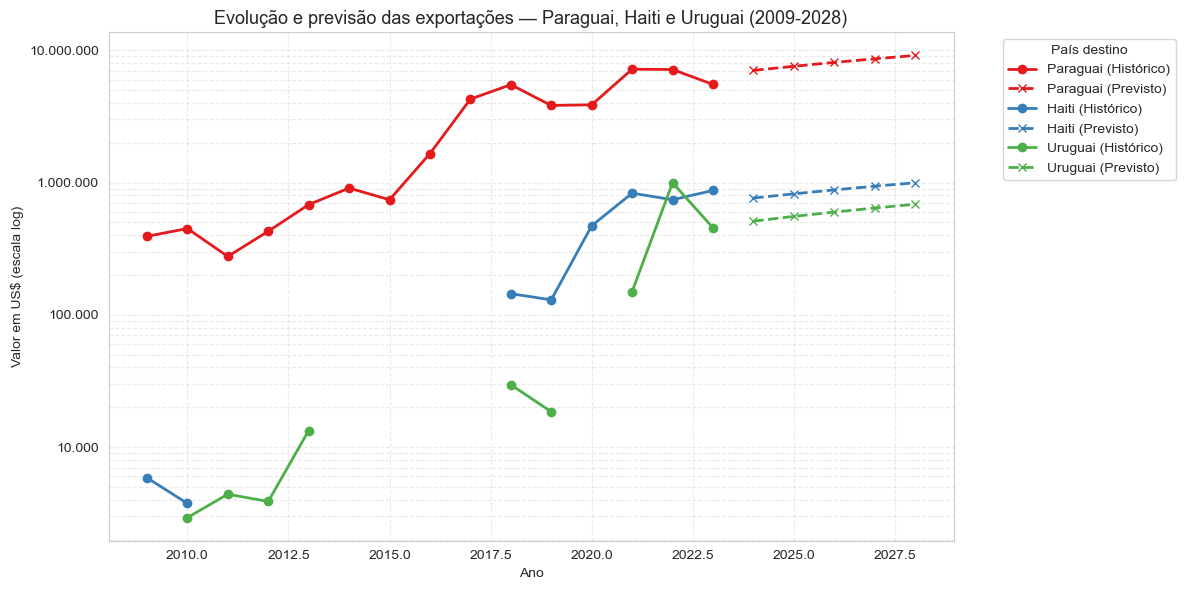

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_style("whitegrid")

# Definir os países desejados
paises_foco = ["Paraguai", "Haiti", "Uruguai"]

# Filtrar pivot_valor apenas para esses países (se existirem)
paises_existentes = [p for p in paises_foco if p in pivot_valor.columns]

# Paleta / mapeamento de cores fixo
palette = sns.color_palette("Set1", n_colors=len(paises_existentes))
color_map = {pais: palette[i] for i, pais in enumerate(paises_existentes)}

plt.figure(figsize=(12,6))
ax = plt.gca()

forecast_results = []
n_periods = 5
last_year = int(pivot_valor.index.max())

for pais in paises_existentes:
    # série anual (pode conter NaN)
    s = pivot_valor[pais].replace(0, np.nan)

    # selecionar anos com dados
    mask = s.notna()
    if mask.sum() < 3:
        continue  # pula se poucos pontos

    X_years = pivot_valor.index.values[mask].reshape(-1, 1)
    y_vals = s[mask].values

    # Treinar regressão linear
    model = LinearRegression()
    model.fit(X_years, y_vals)

    # Previsão para próximos 5 anos
    future_years = np.arange(last_year + 1, last_year + n_periods + 1).reshape(-1, 1)
    forecast = model.predict(future_years)

    # Corrigir previsões negativas
    forecast_clipped = np.clip(forecast, a_min=0, a_max=None)
    forecast_plot = np.where(forecast_clipped > 0, forecast_clipped, np.nan)

    # Guardar previsões
    df_temp = pd.DataFrame({
        "pais_destino": pais,
        "ano": future_years.flatten(),
        "valor_previsto": forecast_clipped
    })
    forecast_results.append(df_temp)

    # Plot histórico
    ax.plot(pivot_valor.index, s, marker='o', linewidth=2, label=f"{pais} (Histórico)", color=color_map[pais])

    # Plot previsão (mesma cor, tracejada)
    ax.plot(future_years.flatten(), forecast_plot, linestyle='--', marker='x', linewidth=2,
            color=color_map[pais], label=f"{pais} (Previsto)")

# Título e labels
ax.set_title(f"Evolução e previsão das exportações — Paraguai, Haiti e Uruguai ({min_year}-{last_year + n_periods})", fontsize=13)
ax.set_xlabel("Ano")
ax.set_ylabel("Valor em US$ (escala log)")

# Escala logarítmica
ax.set_yscale('log')

# Formatação do eixo Y (ponto como separador de milhar)
def br_formatter(x, pos):
    try:
        return f"{int(x):,}".replace(",", ".")
    except Exception:
        return f"{x:.0f}"
ax.yaxis.set_major_formatter(mtick.FuncFormatter(br_formatter))

# Legenda
ax.legend(title="País destino", bbox_to_anchor=(1.05, 1), loc='upper left')

# Grade e layout
ax.grid(True, which="both", linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Consolidar previsões em DataFrame
if forecast_results:
    df_forecast_linear = pd.concat(forecast_results, ignore_index=True)
else:
    df_forecast_linear = pd.DataFrame(columns=["pais_destino", "ano", "valor_previsto"])

# Formatar valores (padrão BR)
df_forecast_linear['valor_previsto'] = df_forecast_linear['valor_previsto'].round().astype(float)
df_forecast_formatado = df_forecast_linear.copy()
df_forecast_formatado['valor_previsto'] = df_forecast_formatado['valor_previsto'].apply(
    lambda x: f"{int(x):,}".replace(",", ".")
)

# display(df_forecast_formatado)

In [13]:
# Lista com a ordem desejada
paises_filtro = ["Paraguai", "Haiti", "Uruguai"]

# Garantir que o campo 'ano' é numérico
df_forecast_formatado['ano'] = pd.to_numeric(df_forecast_formatado['ano'], errors='coerce')

# Pivotar: países nas linhas e anos nas colunas
df_forecast_pivot = df_forecast_formatado.pivot(
    index='pais_destino',
    columns='ano',
    values='valor_previsto'
).reset_index()

# Corrigir o nome das colunas e ordenar os anos (mantendo 'pais_destino' primeiro)
df_forecast_pivot.columns.name = None
cols = ['pais_destino'] + sorted([c for c in df_forecast_pivot.columns if c != 'pais_destino'])
df_forecast_pivot = df_forecast_pivot[cols]

# Filtrar apenas Paraguai, Uruguai e Haiti
df_forecast_pivot = df_forecast_pivot[df_forecast_pivot['pais_destino'].isin(paises_filtro)]

# Garantir a ordem customizada
ordem_customizada = pd.CategoricalDtype(categories=paises_filtro, ordered=True)
df_forecast_pivot['pais_destino'] = df_forecast_pivot['pais_destino'].astype(ordem_customizada)
df_forecast_pivot = df_forecast_pivot.sort_values('pais_destino').reset_index(drop=True)

# Exibir tabela final
display(df_forecast_pivot)


,pais_destino,2024,2025,2026,2027,2028
0,Paraguai,7.046.229,7.569.823,8.093.417,8.617.010,9.140.604
1,Haiti,763.420,821.590,879.760,937.931,996.101
2,Uruguai,511.010,554.666,598.322,641.978,685.634


Por fim temos um retrato dos paises TOP 3 de exportacao em valores (US$) e TOP 3 crescimento acumulado unificados na mesma tabela.

In [43]:
paises_filtro = ["Paraguai", "Estados Unidos", "China", "Haiti", "Uruguai"]

df_crescimento_top3 = df_crescimento_fmt[
    df_crescimento_fmt["pais_destino"].isin(paises_filtro)
].reset_index(drop=True)

# Definir ordem personalizada
ordem_customizada = pd.CategoricalDtype(categories=paises_filtro, ordered=True)
df_crescimento_top3["pais_destino"] = df_crescimento_top3["pais_destino"].astype(ordem_customizada)

# Ordenar conforme a ordem desejada
df_crescimento_top3 = df_crescimento_top3.sort_values("pais_destino").reset_index(drop=True)

display(df_crescimento_top3)

,pais_destino,ano_inicial,ano_final,valor_inicial,valor_final,valor_total,crescimento_acumulado_%,CAGR_%
0,Paraguai,2009,2023,392.087,5.517.263,42.862.206,1307.2%,20.79%
1,Estados Unidos,2009,2023,660.066,429.091,9.309.051,-35.0%,-3.03%
2,China,2009,2023,482.400,183.096,4.903.695,-62.0%,-6.69%
3,Haiti,2009,2023,5.863,871.661,3.198.849,14767.1%,42.94%
4,Uruguai,2010,2023,2.929,454.271,1.674.149,15409.4%,47.40%


## 6. Conclusão
Ao detalhar melhor os dados de exportação dos últimos 15 anos, foi possível visualizar que o **Paraguai** é possivelmente o investimento **mais seguro**, com valores de exportação crescentes e tendência de alta para os próximos anos. 

**EUA** e **China** são grandes mercados que não devem ser subestimados, no entanto apontam tendência de retração para os próximos anos. Considerar seleção de produtos destinados a esses países, talvez produtos mais **premium** com alto valor agregado.

Também devem-se considerar o **Haiti** e o **Uruguai**, embora menores, mas que possuem altíssimo índice de crescimento acumulado e grande tendência de alta, podendo ser um grande **potencial** no futuro.